# Kernel · Silage or Grain on BARC labeled fields (2021–2023)

Combines the **BARC fields explorer** (labels) with the **Sentinel-2 starter** (time series) and adds:

1. One Sentinel-2 load per year over the whole BARC area (not one per field)
2. Per-field, per-date medians of **NDVI** (greenness), **NDMI** (moisture) and **NDTI** (residue)
3. Kernel features: cut date, green at cut, drop speed, dry-down days, moisture before cut, residue after cut
4. Baselines: majority class, the organizers' NDVI-decline-date rule, single-feature rules
5. Small interpretable models (logistic regression, depth-2 tree), with **held-out years** and **held-out fields**
6. An abstain band ("review") and one plain-English sentence per field-year (seed for the Nemotron Harvest Story)

Finds `04_Evaluation/BARC_Corn.2021-2023.gpkg` automatically from the workspace root or a subfolder. Run top to bottom.
The time-series table is cached to `barc_timeseries.csv`, so after the first run you can skip the download cells.

With 44 labels (12 silage), keep models small. XGBoost belongs to the scale-up step, not here.

In [1]:
%pip install geopandas matplotlib numpy pandas odc-stac planetary-computer pystac-client xarray rasterio scikit-learn pyogrio

Note: you may need to restart the kernel to use updated packages.


## 1. Settings

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

_GPKG = "BARC_Corn.2021-2023.gpkg"
DATA_PATH = next((p for p in [Path(_GPKG), Path("04_Evaluation") / _GPKG, Path("../04_Evaluation") / _GPKG,
                              Path("/workspace/04_Evaluation") / _GPKG] if p.exists()), Path(_GPKG))
LAYER = "barc_silage_grain_corn20212023"
YEARS = [2021, 2022, 2023]
SEASON = ("05-01", "11-30")      # May catches the green-up and peak; the guide's July start can miss the peak
MAX_SCENE_CLOUD = 70             # loose at scene level; the SCL pixel mask does the real cloud work
LOAD_CRS = "EPSG:32618"          # UTM 18N for Maryland. The starter's EPSG:32610 is California.
INNER_BUFFER_M = 10              # shrink fields by one pixel so edge pixels don't mix in roads/trees
MIN_VALID_FRAC = 0.5             # a date counts for a field only if at least half its pixels are clear
APPLY_S2_OFFSET = True           # Planetary Computer L2A: subtract 1000 for processing baseline >= 04.00
CACHE = Path("barc_timeseries.csv")

## 2. Labels: one row per field-year (from the BARC explorer)

In [2]:
import geopandas as gpd

fields = gpd.read_file(DATA_PATH, layer=LAYER)
LABEL_COLUMNS = {"Corn_2021": 2021, "Corn_2022": 2022, "Corn_2023": 2023}
labels = (
    fields.melt(id_vars=["OBJECTID", "FIELD", "ACRES", "geometry"], value_vars=list(LABEL_COLUMNS),
                var_name="col", value_name="harvest_type")
    .assign(year=lambda d: d["col"].map(LABEL_COLUMNS))
    .query("harvest_type in ['Grain', 'Silage']")
    .drop(columns=["col", "geometry"])
    .reset_index(drop=True)
)
print(labels.groupby(["year", "harvest_type"]).size().unstack(fill_value=0))

# Fields in the load CRS, shrunk inward; fall back to the original shape if the buffer erases a small field
fields_utm = fields.to_crs(LOAD_CRS)
fields_utm["geom_core"] = [
    g.buffer(-INNER_BUFFER_M) if not g.buffer(-INNER_BUFFER_M).is_empty else g
    for g in fields_utm.geometry
]

harvest_type  Grain  Silage
year                       
2021             14       4
2022              3       4
2023             15       4


## 3. Download: one Sentinel-2 cube per year, then per-field medians per date

Skip this section if `barc_timeseries.csv` already exists.

In [6]:
import planetary_computer
import xarray as xr
from odc.stac import load
from pystac_client import Client
from rasterio.features import rasterize

catalog = Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                      modifier=planetary_computer.sign_inplace)
bbox = tuple(fields.to_crs("EPSG:4326").total_bounds)
BANDS = ["B04", "B08", "B8A", "B11", "B12", "SCL"]


def s2_offset(item):
    pb = item.properties.get("s2:processing_baseline") or "0"
    try:
        return 1000 if float(pb) >= 4.0 else 0
    except ValueError:
        return 0


def field_series_for_year(year):
    items = list(catalog.search(
        collections=["sentinel-2-l2a"], bbox=bbox,
        datetime=f"{year}-{SEASON[0]}/{year}-{SEASON[1]}",
        query={"eo:cloud_cover": {"lt": MAX_SCENE_CLOUD}},
    ).item_collection())
    print(f"{year}: {len(items)} scenes")
    if not items:
        return pd.DataFrame()

    cube = load(items, bands=BANDS, bbox=bbox, crs=LOAD_CRS, resolution=10, groupby="solar_day")

    # Field id raster on the cube grid
    gbox = cube.odc.geobox
    ids = rasterize(((g, int(i)) for g, i in zip(fields_utm["geom_core"], fields_utm["OBJECTID"])),
                    out_shape=tuple(gbox.shape), transform=gbox.transform, fill=0, dtype="int32")
    ids_flat = ids.ravel()
    in_field = ids_flat > 0

    offsets = {str(it.datetime.date()): s2_offset(it) for it in items}
    rows = []
    for t in cube.time.values:
        day = str(pd.Timestamp(t).date())
        off = offsets.get(day, 0) if APPLY_S2_OFFSET else 0
        sl = cube.sel(time=t)
        raw = {b: sl[b].values.astype("float32").ravel() for b in BANDS[:-1]}
        nodata = np.any([raw[b] == 0 for b in raw], axis=0)
        refl = {b: np.clip((raw[b] - off) / 10000.0, 0, None) for b in raw}
        clear = np.isin(sl["SCL"].values.ravel(), [4, 5, 6, 7]) & ~nodata

        with np.errstate(invalid="ignore", divide="ignore"):
            ndvi = (refl["B08"] - refl["B04"]) / (refl["B08"] + refl["B04"])
            ndmi = (refl["B8A"] - refl["B11"]) / (refl["B8A"] + refl["B11"])
            ndti = (refl["B11"] - refl["B12"]) / (refl["B11"] + refl["B12"])

        df = pd.DataFrame({"OBJECTID": ids_flat[in_field], "clear": clear[in_field],
                           "ndvi": ndvi[in_field], "ndmi": ndmi[in_field], "ndti": ndti[in_field]})
        frac = df.groupby("OBJECTID")["clear"].mean().rename("valid_frac")
        med = df[df["clear"]].groupby("OBJECTID")[["ndvi", "ndmi", "ndti"]].median()
        out = pd.concat([frac, med], axis=1).reset_index()
        out["date"] = pd.Timestamp(day)
        out["year"] = year
        out["s2_offset"] = off
        rows.append(out)
    return pd.concat(rows, ignore_index=True)


if CACHE.exists():
    ts = pd.read_csv(CACHE, parse_dates=["date"])
    print(f"Loaded cached {CACHE} ({len(ts)} rows)")
else:
    parts = []
    for y in YEARS:                                   # each year is saved as soon as it finishes
        part_file = Path(f"barc_ts_{y}.csv")
        if part_file.exists():
            parts.append(pd.read_csv(part_file, parse_dates=["date"]))
            print(f"{y}: loaded from {part_file}")
        else:
            part = field_series_for_year(y)
            part.to_csv(part_file, index=False)
            parts.append(part)
    ts = pd.concat(parts, ignore_index=True)
    ts.to_csv(CACHE, index=False)
    print(f"Saved {CACHE} ({len(ts)} rows)")

# Sanity check: mid-summer corn should peak around NDVI 0.8-0.9. Much lower suggests an offset or CRS problem.
summer = ts[ts["date"].dt.month.isin([7, 8]) & (ts["valid_frac"] >= MIN_VALID_FRAC)]
print("Median July-Aug NDVI over fields:", round(summer["ndvi"].median(), 3))

Loaded cached barc_timeseries.csv (13280 rows)
Median July-Aug NDVI over fields: 0.774


## 4. Kernel features per field-year

Everything runs on the cleaned per-field series. Dates are day-of-year so years line up.

In [7]:
def kernel_features(series, min_valid=0.5, bare_ndvi=0.35):
    """series: one field-year with columns date, ndvi, ndmi, ndti, valid_frac. Returns a dict of features."""
    s = series[(series["valid_frac"] >= min_valid) & series["ndvi"].notna()].sort_values("date")
    s = s.assign(doy=s["date"].dt.dayofyear.astype(int)).reset_index(drop=True)
    f = {"n_obs": len(s)}
    if len(s) < 4:
        return f

    window = s[(s["doy"] >= 150) & (s["doy"] <= 260)]         # June to mid-September
    if window.empty:
        return f
    ip = int(window["ndvi"].idxmax())
    peak = float(s.loc[ip, "ndvi"])
    f.update(peak_ndvi=peak, peak_doy=int(s.loc[ip, "doy"]))
    after = s.loc[ip:].reset_index(drop=True)
    if len(after) < 2:
        return f

    # Organizers' baseline: first date of a sustained NDVI decline (below the halfway point, and stays there)
    floor = float(after["ndvi"].min())
    half = floor + 0.5 * (peak - floor)
    below = (after["ndvi"] < half).to_numpy()
    for i in range(1, len(after)):
        if below[i] and (i == len(after) - 1 or below[i + 1]):
            f["decline_doy"] = int(after.loc[i, "doy"])
            break

    # Biggest single drop between consecutive clear dates = most likely cut
    d_ndvi = after["ndvi"].diff().to_numpy()[1:] * -1
    d_days = after["doy"].diff().to_numpy()[1:]
    k = int(np.nanargmax(d_ndvi)) + 1                         # index of the first date after the drop
    f.update(
        cut_doy=int(after.loc[k, "doy"]),
        cut_gap_days=int(d_days[k - 1]),                      # uncertainty of the cut date
        max_drop=float(d_ndvi[k - 1]),
        max_drop_rate=float(d_ndvi[k - 1] / max(d_days[k - 1], 1)),
        green_at_cut=float(after.loc[k - 1, "ndvi"] / peak) if peak > 0 else np.nan,
        ndmi_before_cut=float(after.loc[k - 1, "ndmi"]),
    )

    # Dry-down: days from first browning (below 90% of peak) to the cut
    browning = after[(after.index < k) & (after["ndvi"] < 0.9 * peak)]
    f["drydown_days"] = int(f["cut_doy"] - browning["doy"].iloc[0]) if len(browning) else 0

    # Residue: earliest up-to-3 clear dates after the cut while the field is no longer green
    post = after.loc[k:]
    post = post[post["ndvi"] < bare_ndvi].head(3)
    f["ndti_post"] = float(post["ndti"].median()) if len(post) else np.nan
    f["ndvi_late"] = float(s.loc[s["doy"] >= 258, "ndvi"].median()) if (s["doy"] >= 258).any() else np.nan
    return f


def build_features(ts, labels, min_valid=0.5):
    rows = []
    for (oid, yr), g in ts.groupby(["OBJECTID", "year"]):
        rows.append({"OBJECTID": oid, "year": yr, **kernel_features(g, min_valid)})
    feats = pd.DataFrame(rows)
    return labels.merge(feats, on=["OBJECTID", "year"], how="left")

In [8]:
feat = build_features(ts, labels, MIN_VALID_FRAC)
feat.to_csv("barc_features.csv", index=False)
show = ["harvest_type", "cut_doy", "decline_doy", "green_at_cut", "max_drop_rate",
        "drydown_days", "ndmi_before_cut", "ndti_post"]
print(feat.groupby("harvest_type")[show[1:]].median().round(3).T)
print("\nField-years with too few clear dates:", int(feat["cut_doy"].isna().sum()))

harvest_type       Grain   Silage
cut_doy          260.500  256.500
decline_doy      260.500  255.000
green_at_cut       0.896    0.912
max_drop_rate      0.028    0.051
drydown_days      20.000   15.000
ndmi_before_cut    0.288    0.378
ndti_post          0.180    0.113

Field-years with too few clear dates: 0


## 5. The money slide: do silage and grain curves look different?

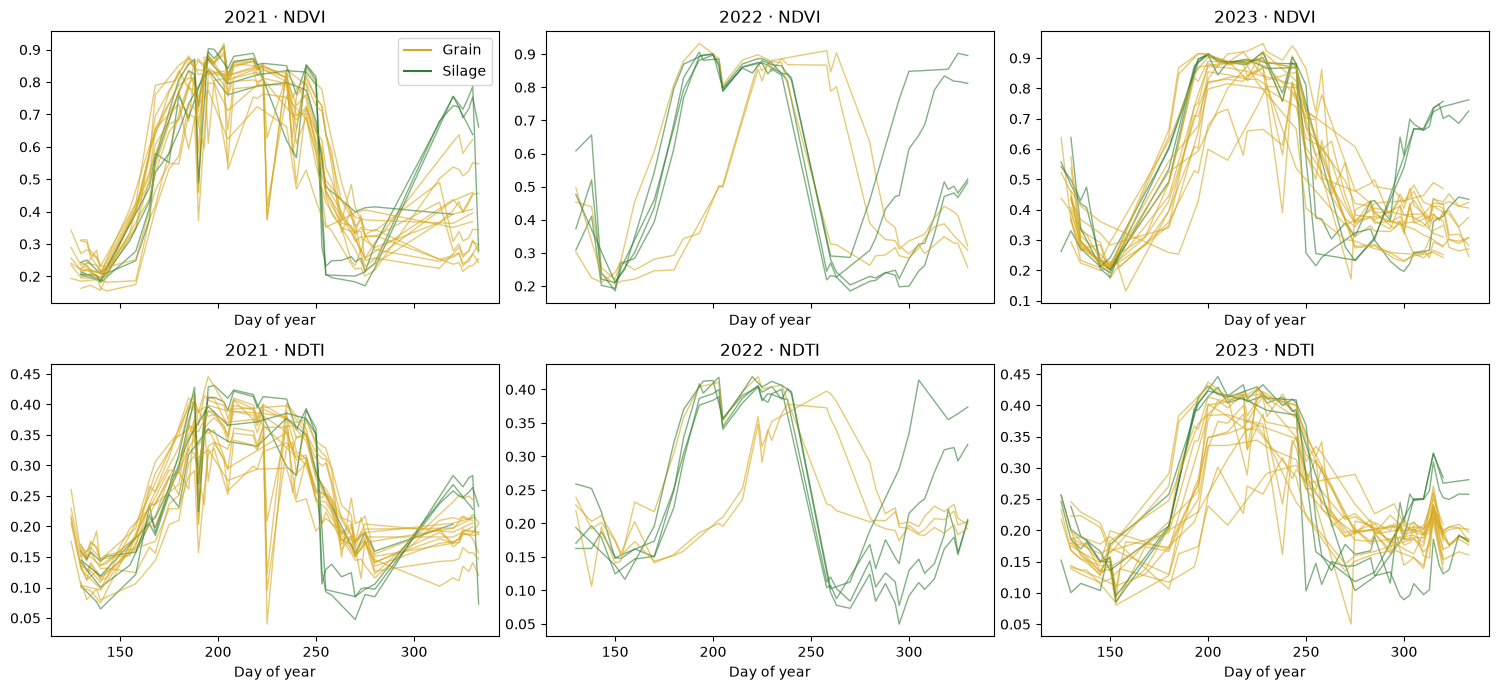

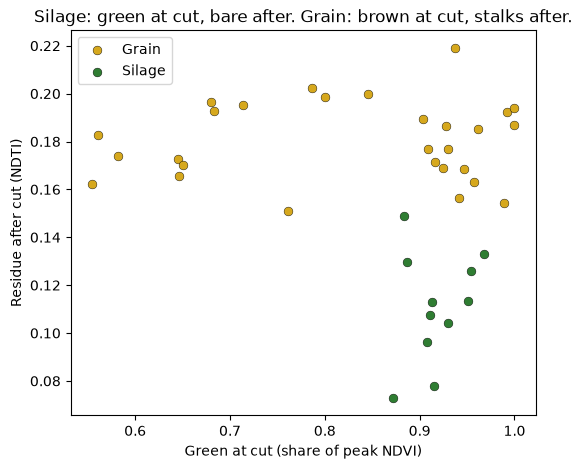

In [9]:
import matplotlib.pyplot as plt

COLORS = {"Grain": "#d6a81d", "Silage": "#2f7d32"}
tsl = ts.merge(labels[["OBJECTID", "year", "harvest_type"]], on=["OBJECTID", "year"])
tsl = tsl[tsl["valid_frac"] >= MIN_VALID_FRAC].assign(doy=lambda d: d["date"].dt.dayofyear)

fig, axes = plt.subplots(2, len(YEARS), figsize=(15, 7), sharex=True)
for j, yr in enumerate(YEARS):
    for row, col in enumerate(["ndvi", "ndti"]):
        ax = axes[row, j]
        for (oid, ht), g in tsl[tsl["year"] == yr].groupby(["OBJECTID", "harvest_type"]):
            ax.plot(g["doy"], g[col], color=COLORS[ht], alpha=0.6, lw=1)
        ax.set_title(f"{yr} · {col.upper()}")
        ax.set_xlabel("Day of year")
for ht, c in COLORS.items():
    axes[0, 0].plot([], [], color=c, label=ht)
axes[0, 0].legend()
plt.tight_layout()
plt.savefig("barc_curves.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for ht, g in feat.groupby("harvest_type"):
    ax.scatter(g["green_at_cut"], g["ndti_post"], color=COLORS[ht], label=ht, s=40, edgecolor="k", lw=0.3)
ax.set(xlabel="Green at cut (share of peak NDVI)", ylabel="Residue after cut (NDTI)",
       title="Silage: green at cut, bare after. Grain: brown at cut, stalks after.")
ax.legend()
plt.savefig("barc_scatter.png", dpi=150)
plt.show()

## 6. Evaluation: baselines vs small models on held-out years and held-out fields

- **Held-out year** (train on 2 years, test on the 3rd): the guide's preferred split.
- **Held-out fields** (GroupKFold on OBJECTID): stops the same field appearing in train and test.

Every threshold and model is fit on the training folds only.

In [10]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text

RULE_FEATURES = ["decline_doy", "cut_doy", "green_at_cut", "max_drop_rate",
                 "drydown_days", "ndmi_before_cut", "ndti_post"]
MODEL_FEATURES = ["cut_doy", "green_at_cut", "max_drop_rate", "drydown_days", "ndmi_before_cut", "ndti_post"]


def fit_threshold(x, y):
    """Best single cut on one feature for the silage class (direction learned). Returns (thr, sign, f1)."""
    x = np.asarray(x, float)
    y = np.asarray(y, int)
    ok = ~np.isnan(x)
    best = (np.nan, 1, -1.0)
    for thr in np.unique(x[ok]):
        for sign in (1, -1):                                   # sign=1: silage if x <= thr
            pred = (sign * x[ok] <= sign * thr).astype(int)
            tp = int(((pred == 1) & (y[ok] == 1)).sum())
            fp = int(((pred == 1) & (y[ok] == 0)).sum())
            fn = int(((pred == 0) & (y[ok] == 1)).sum())
            f1 = 2 * tp / max(2 * tp + fp + fn, 1)
            if f1 > best[2]:
                best = (float(thr), sign, f1)
    return best


def apply_threshold(x, thr, sign, default=0):
    x = np.asarray(x, float)
    out = np.full(len(x), default, int)
    ok = ~np.isnan(x)
    out[ok] = (sign * x[ok] <= sign * thr).astype(int)
    return out


def make_models():
    return {
        "logistic": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                  LogisticRegression(class_weight="balanced", C=0.5, max_iter=1000)),
        "tree_depth2": make_pipeline(SimpleImputer(strategy="median"),
                                     DecisionTreeClassifier(max_depth=2, class_weight="balanced",
                                                            min_samples_leaf=3, random_state=0)),
    }


def splits(df, scheme):
    if scheme == "held_out_year":
        for yr in sorted(df["year"].unique()):
            yield df.index[df["year"] != yr], df.index[df["year"] == yr]
    else:
        n = min(5, df["OBJECTID"].nunique())
        for tr, te in GroupKFold(n_splits=n).split(df, groups=df["OBJECTID"]):
            yield df.index[tr], df.index[te]


def cross_validate(df, scheme):
    df = df.reset_index(drop=True)
    y = (df["harvest_type"] == "Silage").astype(int).to_numpy()
    preds = {"majority (always grain)": np.zeros(len(df), int)}
    preds.update({f"rule: {c}": np.zeros(len(df), int) for c in RULE_FEATURES})
    probs = {m: np.full(len(df), np.nan) for m in make_models()}
    for tr, te in splits(df, scheme):
        for c in RULE_FEATURES:
            thr, sign, _ = fit_threshold(df.loc[tr, c], y[tr])
            if not np.isnan(thr):
                preds[f"rule: {c}"][te] = apply_threshold(df.loc[te, c], thr, sign)
        if len(np.unique(y[tr])) < 2:
            continue
        for name, model in make_models().items():
            model.fit(df.loc[tr, MODEL_FEATURES], y[tr])
            probs[name][te] = model.predict_proba(df.loc[te, MODEL_FEATURES])[:, 1]
    for name, p in probs.items():
        preds[f"model: {name}"] = (np.nan_to_num(p, nan=0.0) >= 0.5).astype(int)
    return y, preds, probs


def scores(y, p):
    tp = int(((p == 1) & (y == 1)).sum()); fp = int(((p == 1) & (y == 0)).sum())
    fn = int(((p == 0) & (y == 1)).sum()); tn = int(((p == 0) & (y == 0)).sum())
    def prf(tp, fp, fn):
        pr = tp / (tp + fp) if tp + fp else 0.0
        rc = tp / (tp + fn) if tp + fn else 0.0
        return pr, rc, (2 * pr * rc / (pr + rc) if pr + rc else 0.0)
    sp, sr, sf = prf(tp, fp, fn)
    gp, gr, gf = prf(tn, fn, fp)
    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "silage_precision": sp, "silage_recall": sr, "silage_F1": sf,
            "grain_precision": gp, "grain_recall": gr, "grain_F1": gf,
            "accuracy": (tp + tn) / len(y)}


def results_table(df):
    out = []
    for scheme in ["held_out_year", "held_out_fields"]:
        y, preds, _ = cross_validate(df, scheme)
        for name, p in preds.items():
            out.append({"split": scheme, "method": name, **scores(y, p)})
    return pd.DataFrame(out)


def abstain_report(y, prob, low=0.35, high=0.65):
    ok = ~np.isnan(prob)
    decided = ok & ((prob <= low) | (prob >= high))
    p = (prob[decided] >= 0.5).astype(int)
    return {"coverage": decided.mean(), "n_review": int((ok & ~decided).sum()),
            **{f"decided_{k}": v for k, v in scores(y[decided], p).items()
               if k in ("silage_precision", "silage_recall", "silage_F1", "accuracy")}}

In [11]:
res = results_table(feat)
res.to_csv("barc_results.csv", index=False)
cols = ["split", "method", "TP", "FP", "FN", "TN", "silage_precision", "silage_recall", "silage_F1", "grain_F1"]
print(res[cols].round(2).sort_values(["split", "silage_F1"], ascending=[True, False]).to_string(index=False))

          split                  method  TP  FP  FN  TN  silage_precision  silage_recall  silage_F1  grain_F1
held_out_fields         model: logistic  11   1   1  31              0.92           0.92       0.92      0.97
held_out_fields      model: tree_depth2  10   1   2  31              0.91           0.83       0.87      0.95
held_out_fields         rule: ndti_post   9   0   3  32              1.00           0.75       0.86      0.96
held_out_fields       rule: decline_doy  11  16   1  16              0.41           0.92       0.56      0.65
held_out_fields   rule: ndmi_before_cut   8   9   4  23              0.47           0.67       0.55      0.78
held_out_fields      rule: green_at_cut  11  18   1  14              0.38           0.92       0.54      0.60
held_out_fields           rule: cut_doy  10  22   2  10              0.31           0.83       0.45      0.45
held_out_fields     rule: max_drop_rate   7  16   5  16              0.30           0.58       0.40      0.60
held_out_f

### Results by year (the challenge asks for counts and performance by year and class)

In [12]:
def per_year_table(df, methods, scheme="held_out_year"):
    df = df.reset_index(drop=True)
    y, preds, _ = cross_validate(df, scheme)
    rows = []
    for m in methods:
        for yr in sorted(df["year"].unique()):
            idx = (df["year"] == yr).to_numpy()
            rows.append({"method": m, "year": yr, "n_grain": int((y[idx] == 0).sum()),
                         "n_silage": int((y[idx] == 1).sum()), **scores(y[idx], preds[m][idx])})
    return pd.DataFrame(rows)

In [13]:
by_year = per_year_table(feat, ["rule: decline_doy", "model: logistic", "model: tree_depth2"])
by_year.to_csv("barc_results_by_year.csv", index=False)
print(by_year[["method", "year", "n_grain", "n_silage", "TP", "FP", "FN", "TN",
               "silage_recall", "grain_recall"]].round(2).to_string(index=False))

# Field 231 was silage in 2022 and grain in 2023: a good check that the model reads the season, not the field
print(feat.loc[feat["OBJECTID"] == 231, ["year", "harvest_type", "cut_doy", "green_at_cut", "ndti_post"]])

            method  year  n_grain  n_silage  TP  FP  FN  TN  silage_recall  grain_recall
 rule: decline_doy  2021       14         4   4  11   0   3           1.00          0.21
 rule: decline_doy  2022        3         4   0   0   4   3           0.00          1.00
 rule: decline_doy  2023       15         4   3   4   1  11           0.75          0.73
   model: logistic  2021       14         4   3   4   1  10           0.75          0.71
   model: logistic  2022        3         4   4   0   0   3           1.00          1.00
   model: logistic  2023       15         4   4   0   0  15           1.00          1.00
model: tree_depth2  2021       14         4   3   0   1  14           0.75          1.00
model: tree_depth2  2022        3         4   4   0   0   3           1.00          1.00
model: tree_depth2  2023       15         4   3   0   1  15           0.75          1.00
    year harvest_type  cut_doy  green_at_cut  ndti_post
18  2022       Silage      258      0.912771    0.1128

### Abstain band ("review") and explainable model on all data

Report coverage honestly: the share of fields the model will call, and how good those calls are.

In [14]:
y_all, _, probs = cross_validate(feat, "held_out_year")
for name, p in probs.items():
    print(name, {k: round(v, 2) if isinstance(v, float) else v for k, v in abstain_report(y_all, p).items()})

# Fit the depth-2 tree on everything, only to show the rules it learns (not for scoring)
tree = make_models()["tree_depth2"]
tree.fit(feat[MODEL_FEATURES], (feat["harvest_type"] == "Silage").astype(int))
print(export_text(tree[-1], feature_names=MODEL_FEATURES))

logistic {'coverage': np.float64(0.91), 'n_review': 4, 'decided_silage_precision': 0.71, 'decided_silage_recall': 0.91, 'decided_silage_F1': 0.8, 'decided_accuracy': 0.88}
tree_depth2 {'coverage': np.float64(1.0), 'n_review': 0, 'decided_silage_precision': 1.0, 'decided_silage_recall': 0.83, 'decided_silage_F1': 0.91, 'decided_accuracy': 0.95}
|--- ndti_post <= 0.15
|   |--- class: 1
|--- ndti_post >  0.15
|   |--- ndmi_before_cut <= 0.17
|   |   |--- class: 0
|   |--- ndmi_before_cut >  0.17
|   |   |--- class: 0



## 7. One sentence per field-year (input for the Nemotron Harvest Story agent)

In [15]:
def doy_to_date(year, doy):
    return (pd.Timestamp(f"{int(year)}-01-01") + pd.Timedelta(days=int(doy) - 1)).strftime("%b %d")


def explain(row):
    if pd.isna(row.get("cut_doy")):
        return "Not enough clear images to see the harvest; flagged for review."
    parts = [f"Cut around {doy_to_date(row['year'], row['cut_doy'])} (±{int(row['cut_gap_days'])} days)",
             f"with {row['green_at_cut']:.0%} of peak greenness still on the field"]
    parts.append("and almost no browning first" if row["drydown_days"] <= 7
                 else f"after about {int(row['drydown_days'])} days of browning")
    if not pd.isna(row.get("ndti_post")):
        parts.append(f"; ground afterward looks {'bare' if row['ndti_post'] < 0.08 else 'covered in stalks'}"
                     f" (NDTI {row['ndti_post']:.2f})")
    return " ".join(parts[:3]) + "".join(parts[3:]) + "."

In [16]:
feat["explanation"] = feat.apply(explain, axis=1)
feat[["OBJECTID", "year", "harvest_type", "explanation"]].to_csv("barc_explanations.csv", index=False)
feat[["OBJECTID", "year", "harvest_type", "explanation"]].head(10)

,OBJECTID,year,harvest_type,explanation
0,1,2021,Grain,Cut around Jul 24 (±2 days) with 94% of peak g...
1,24,2021,Grain,Cut around Aug 28 (±5 days) with 92% of peak g...
2,238,2021,Grain,Cut around Aug 13 (±2 days) with 96% of peak g...
3,280,2021,Silage,Cut around Sep 10 (±3 days) with 89% of peak g...
4,286,2021,Grain,Cut around Sep 12 (±2 days) with 65% of peak g...
5,288,2021,Grain,Cut around Sep 20 (±5 days) with 65% of peak g...
6,291,2021,Silage,Cut around Nov 29 (±3 days) with 87% of peak g...
7,327,2021,Silage,Cut around Sep 12 (±5 days) with 81% of peak g...
8,328,2021,Silage,Cut around Sep 12 (±5 days) with 91% of peak g...
9,332,2021,Grain,Cut around Sep 27 (±15 days) with 56% of peak ...


## Notes for the write-up

- **Sources:** Planetary Computer `sentinel-2-l2a` (L2A surface reflectance), bands B04, B08, B8A, B11, B12, SCL,
  loaded at 10 m in EPSG:32618; SCL classes 4–7 kept. BARC labels: cite Dulaney et al. 2024 and Kraatz 2023.
- **Offset:** 1000 subtracted for processing baseline ≥ 04.00 (column `s2_offset` records it per date).
  If you switch to Earth Search `sentinel-2-c1-l2a`, set `APPLY_S2_OFFSET = False` (already harmonized).
- **No interpolation:** features use clear dates only. `cut_gap_days` is the honest uncertainty on the cut date.
- **Limits:** one research farm in Maryland, 44 labels, 12 silage. Results show the signal exists; they do not
  prove it transfers to California or the Corn Belt. NDTI thresholds are illustrative until fitted.
- **Abstain:** model probabilities between 0.35 and 0.65 → "review". Report coverage next to the metrics.